--- Step 1: Loading Data ---
Successfully loaded sales_data.csv

--- Step 2: Unifying and Cleaning Data ---
Successfully unified data. Total rows before cleaning: 2823
Total columns before cleaning: 25

First 5 rows of the combined data:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 

C:\Users\lalit\AppData\Local\Temp\ipykernel_8496\2678048657.py:124: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sales = sales_df.set_index('ORDERDATE')['TotalSales'].resample('M').sum()


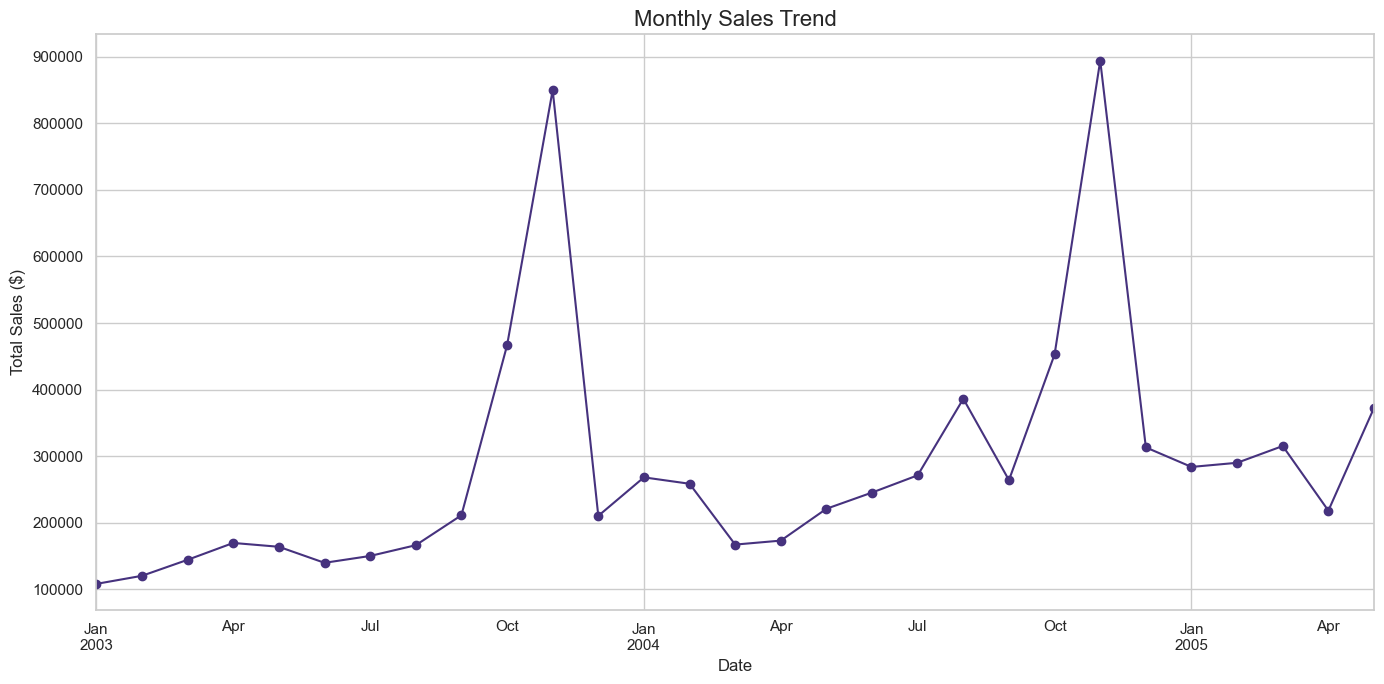

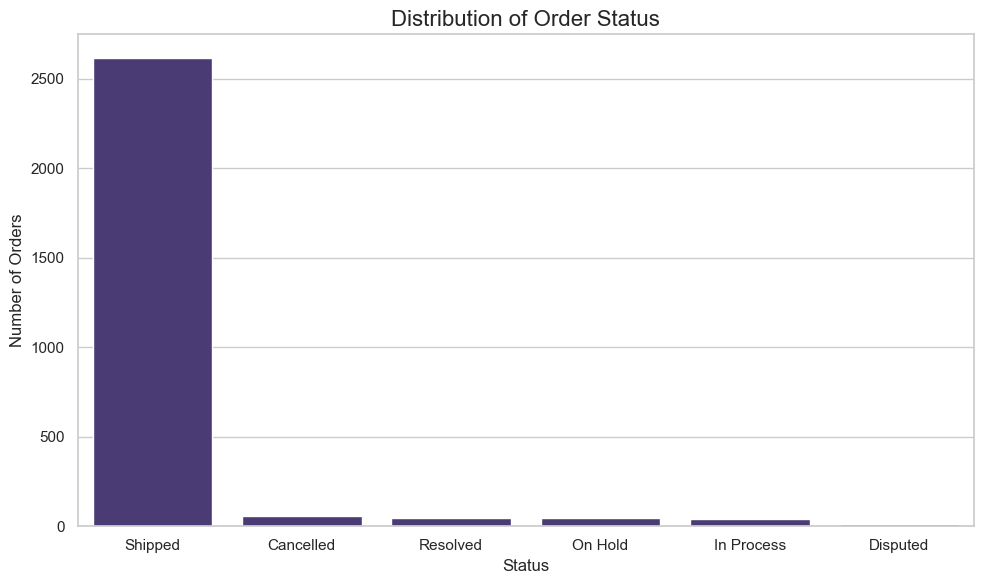

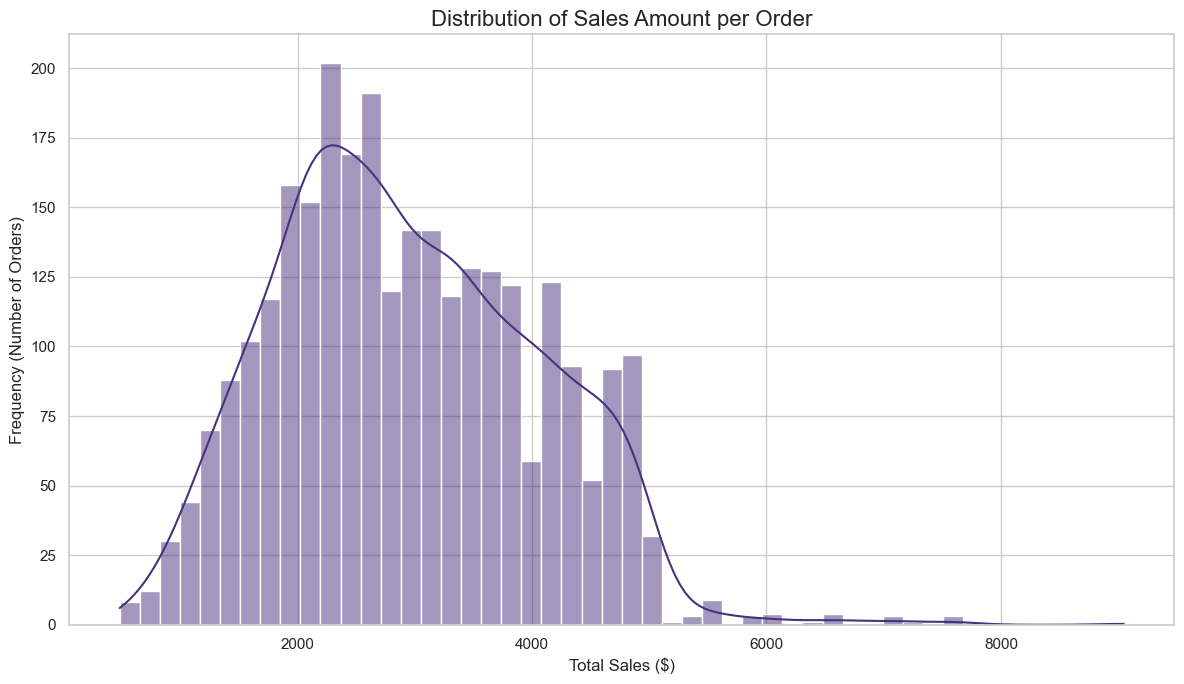

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Step 1: Loading Data ---")

data_frames = []

try:
    csv_df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
    data_frames.append(csv_df)
    print("Successfully loaded sales_data.csv")
except FileNotFoundError:
    print("Warning: sales_data.csv not found.")

try:
    excel_df = pd.read_excel('/content/Sample-Sales-Data.xlsx')
    data_frames.append(excel_df)
    print("Successfully loaded sales_data.xlsx")
except FileNotFoundError:
    print("Warning: sales_data.xlsx not found.")

try:
    # This try-except block now handles different JSON structures    automatically
    try:
        json_df = pd.read_json('/content/customers.json')
    except ValueError:
        json_df = pd.read_json('/content/customers.json', lines=True)
    data_frames.append(json_df)
    print("Successfully loaded sales_data.json")
except FileNotFoundError:
    print("Warning: sales_data.json not found.")



print("\n--- Step 2: Unifying and Cleaning Data ---")

sales_df = pd.concat(data_frames, ignore_index=True)
print(f"Successfully unified data. Total rows before cleaning: {len(sales_df)}")
print(f"Total columns before cleaning: {len(sales_df.columns)}")

# --- Data Exploration ---
print("\nFirst 5 rows of the combined data:")
print(sales_df.head())

 # --- Data Cleaning --
for col in sales_df.columns:
     if sales_df[col].apply(type).eq(dict).any():
         print(f"Found dictionaries in column '{col}'. Converting to string.")
         sales_df[col] = sales_df[col].astype(str)

for col in sales_df.select_dtypes(include=['number']).columns:
     sales_df[col] = sales_df[col].fillna(0)
print("\nFilled missing numerical values with 0.")

initial_rows = len(sales_df)
sales_df.drop_duplicates(inplace=True)
print(f"Removed {initial_rows - len(sales_df)} duplicate rows.")
print(f"Total rows after cleaning: {len(sales_df)}")



print("\n--- Step 3: Transforming Data ---")

# Let's use the column names from your output: 'QUANTITYORDERED' and 'PRICEEACH'
if 'QUANTITYORDERED' in sales_df.columns and 'PRICEEACH' in sales_df.columns:
    sales_df['TotalSales'] = sales_df['QUANTITYORDERED'] * sales_df['PRICEEACH']
    print("Created 'TotalSales' column.")
else:
     print("Warning: 'QUANTITYORDERED' or 'PRICEEACH' not found. Cannot create 'TotalSales'.")

if 'ORDERDATE' in sales_df.columns:
     sales_df['ORDERDATE'] = pd.to_datetime(sales_df['ORDERDATE'], errors='coerce')
     print("Converted 'ORDERDATE' column to datetime format.")
print("\nData after transformations:")
sales_df.head()




print("\n--- Step 4: Analyzing Data ---")

if 'TotalSales' in sales_df.columns:
    print("\nDescriptive Statistics:")
    print(sales_df[['QUANTITYORDERED', 'PRICEEACH', 'TotalSales']].describe())

    total_revenue = sales_df['TotalSales'].sum()
    print(f"\nTotal Sales Revenue: ${total_revenue:,.2f}")






print("\n--- Step 5: Visualizing Data ---")

# Set plot style for all visualizations
sns.set_theme(style="whitegrid", palette="viridis")





# --- Plot 1: Total Sales by Year (Bar Plot) ---
if 'Year' in sales_df.columns and 'TotalSales' in sales_df.columns:
    plt.figure(figsize=(10, 6))
    sales_by_year = sales_df.groupby('Year')['TotalSales'].sum().reset_index()
    sns.barplot(x='Year', y='TotalSales', data=sales_by_year)
    plt.title('Total Sales by Year', fontsize=16)
    plt.ylabel('Total Sales ($ Millions)')
    plt.xlabel('Year')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()







# --- Plot 2: Sales Trend Over Time (Line Plot) ---
if 'ORDERDATE' in sales_df.columns and 'TotalSales' in sales_df.columns:
    monthly_sales = sales_df.set_index('ORDERDATE')['TotalSales'].resample('M').sum()
    plt.figure(figsize=(14, 7))
    monthly_sales.plot(kind='line', marker='o', linestyle='-')
    plt.title('Monthly Sales Trend', fontsize=16)
    plt.ylabel('Total Sales ($)')
    plt.xlabel('Date')
    plt.grid(True)
    plt.tight_layout()
    plt.show()






# --- Plot 3: Order Status Distribution (Count Plot) ---
if 'STATUS' in sales_df.columns:
    plt.figure(figsize=(10, 6))
    sns.countplot(x='STATUS', data=sales_df, order=sales_df['STATUS'].value_counts().index)
    plt.title('Distribution of Order Status', fontsize=16)
    plt.ylabel('Number of Orders')
    plt.xlabel('Status')
    plt.tight_layout()
    plt.show()




# --- Plot 4: Distribution of Sales Amount per Transaction (Histogram) ---
if 'TotalSales' in sales_df.columns:
    plt.figure(figsize=(12, 7))
    # Add a KDE plot for a smooth distribution line
    sns.histplot(sales_df['TotalSales'], bins=50, kde=True)
    plt.title('Distribution of Sales Amount per Order', fontsize=16)
    plt.ylabel('Frequency (Number of Orders)')
    plt.xlabel('Total Sales ($)')
    plt.tight_layout()
    plt.show()
